EXTRACCIÓN

In [ ]:
!pip install confluent-kafka

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 15.7 MB/s  0:00:00


In [ ]:
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


In [ ]:
import pandas as pd
from google.colab import userdata
from confluent_kafka import Consumer
import json
import certifi



# Configuración del consumidor para una nueva lectura limpia desde el inicio
conf_analisis = {
    "bootstrap.servers": "kafka-classroom-2026.westus.cloudapp.azure.com:9092",
    "security.protocol": "SASL_SSL",
    "sasl.mechanisms": "SCRAM-SHA-512",
    "sasl.username": "classroom-students",
    "sasl.password": userdata.get("KAFKA_DANIEL"),
    "ssl.ca.location": certifi.where(),
    "group.id": "carlos-fabian-cordoba-1",
    "auto.offset.reset": "earliest"
}

consumer = Consumer(conf_analisis)
consumer.subscribe(['etl.records'])

# Lista para almacenar los registros planos estructurados
eventos_procesados = []

print("Consumiendo y estructurando todos los mensajes históricos...")

try:
    intentos = 0
    while intentos < 10:
        msg = consumer.poll(timeout=1.0)

        if msg is None:
            intentos += 1
            continue

        if msg.error():
            print(f"Error: {msg.error()}")
            continue

        # Decodificar el mensaje
        valor_decodificado = msg.value().decode('utf-8')
        datos = json.loads(valor_decodificado)


        # registro_plano = {
        #     'metadata': {'source_file': '2019.csv', 'year': 2019, 'record_id': '2019-151'},
        #     'data': {'Overall rank': 151,'Country or region': 'Yemen','Score': 3.38,'GDP per capita': 0.287,'Social support': 1.163,'Healthy life expectancy': 0.463,'Freedom to make life choices': 0.143,'Generosity': 0.108,'Perceptions of corruption': 0.077}
        # }

        #  registro_plano = {
        #     'metadata':
        #           {
        #               'source_file':'2019.csv',
        #               'year': 2019,
        #               'record_id':'2019-151'
        #           },
        #     'data':
        #           {
        #               'Overall rank': 151,
        #               'Country or region': 'Yemen',
        #               'Score': 3.38,
        #               'GDP per capita': 0.287,
        #               'Social support': 1.163,
        #               'Healthy life expectancy': 0.463,
        #               'Freedom to make life choices': 0.143,
        #               'Generosity': 0.108,
        #               'Perceptions of corruption': 0.077
        #           }
        #  }



        # Lo siguiente toca hacerlo, pues los datos se encuentran en dos campos anidados:
        # Extraemos los campos del JSON anidado de forma segura
        metadata = datos.get('metadata', {})
        data_fields = datos.get('data', {})


        registro_plano = {
            "source_file": metadata.get("source_file", "N/A"),
            "year": metadata.get("year", None),
            "record_id": metadata.get("record_id", "N/A"),
        }

        for clave, valor in data_fields.items():
            registro_plano[clave] = valor


        # Agregamos a nuestra lista
        eventos_procesados.append(registro_plano)
        intentos = 0  # Reseteamos intentos al recibir datos

    print(f"\n¡Consumo completado! Se han recuperado {len(eventos_procesados)} eventos.")

except KeyboardInterrupt:
    print("\nConsumo detenido manualmente.")
finally:
    consumer.close()

# Convertimos la lista de eventos a un DataFrame de Pandas
df_eventos = pd.DataFrame(eventos_procesados)

# Mostramos las primeras filas de los datos recuperados
display(df_eventos.head(5))

Consumiendo y estructurando todos los mensajes históricos...

¡Consumo completado! Se han recuperado 782 eventos.


,source_file,year,record_id,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual,Lower Confidence Interval,Upper Confidence Interval,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Health..Life.Expectancy.,Trust..Government.Corruption.,Dystopia.Residual,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Perceptions of corruption
0,2015.csv,2015,2015-4,Norway,Western Europe,4.0,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015.csv,2015,2015-6,Finland,Western Europe,6.0,7.406,0.03140,1.29025,1.31826,0.88911,0.64169,0.41372,0.23351,2.61955,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015.csv,2015,2015-8,Sweden,Western Europe,8.0,7.364,0.03157,1.33171,1.28907,0.91087,0.65980,0.43844,0.36262,2.37119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015.csv,2015,2015-9,New Zealand,Australia and New Zealand,9.0,7.286,0.03371,1.25018,1.31967,0.90837,0.63938,0.42922,0.47501,2.26425,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015.csv,2015,2015-12,Costa Rica,Latin America and Caribbean,12.0,7.226,0.04454,0.95578,1.23788,0.86027,0.63376,0.10583,0.25497,3.17728,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2015.csv,2015,2015-15,United States,North America,15.0,7.119,0.03839,1.39451,1.24711,0.86179,0.54604,0.15890,0.40105,2.51011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2015.csv,2015,2015-18,Ireland,Western Europe,18.0,6.940,0.03676,1.33596,1.36948,0.89533,0.61777,0.28703,0.45901,1.97570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2015.csv,2015,2015-19,Belgium,Western Europe,19.0,6.937,0.03595,1.30782,1.28566,0.89667,0.58450,0.22540,0.22250,2.41484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2015.csv,2015,2015-21,United Kingdom,Western Europe,21.0,6.867,0.01866,1.26637,1.28548,0.90943,0.59625,0.32067,0.51912,1.96994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2015.csv,2015,2015-24,Singapore,Southeastern Asia,24.0,6.798,0.03780,1.52186,1.02000,1.02525,0.54252,0.49210,0.31105,1.88501,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
!pip install sqlalchemy

In [ ]:
import sqlalchemy
from sqlalchemy import create_engine, URL, text
import pandas as pd
from google.colab import userdata
import warnings
import io
import csv


#credenciales de acceso (yo)
HOST = "aws-0-us-east-1.pooler.supabase.com" #frase
PORT= 6543
PASSWORD = userdata.get('SUPDANEOWN')
DATABASE = "postgres"
USER = "postgres.pnubntjdyhzsfzngmzjk"
DIALECTO = "postgresql+psycopg2"

#url para el motor (yo)
conexion = URL.create(
  drivername=DIALECTO,
  database= DATABASE,
  password= PASSWORD,
  host= HOST,
  port=PORT,
  username=USER
  )

#motor (yo)
engine = create_engine(url=conexion)

#escritura a supabase (yo)
df_eventos.to_sql(
    name="ranking_felicidad",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
    )



782

FIN DE LA EXTRACCIÓN Y EL GUARDADO

EDA

In [ ]:
# import sqlalchemy
# from sqlalchemy import create_engine, URL, text
# import pandas as pd
# from google.colab import userdata
# import warnings
# import io
# import csv

In [19]:
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)

In [8]:
import sqlalchemy
from sqlalchemy import create_engine, URL, text
import pandas as pd
from google.colab import userdata
import warnings
import io


HOST = "aws-0-us-east-1.pooler.supabase.com" #frase
PORT= 6543
PASSWORD = userdata.get('SUPDANEOWN')
DATABASE = "postgres"
USER = "postgres.pnubntjdyhzsfzngmzjk"
DIALECTO = "postgresql+psycopg2"

#url para el motor (yo)
conexion = URL.create(
  drivername=DIALECTO,
  database= DATABASE,
  password= PASSWORD,
  host= HOST,
  port=PORT,
  username=USER
  )

engine= create_engine(url=conexion)

srce_files= ['2015.csv','2016.csv','2017.csv','2018.csv','2019.csv']
dict_pandas_felic={}

for file in srce_files:
  query=text(
    f"""
      SELECT *
      FROM ranking_felicidad
      WHERE source_file='{file}'

    """
    )

  with engine.connect() as conn:
    resultado=pd.read_sql(query, con=conn)
    dict_pandas_felic[file]=resultado


clmns_arc2015_2016= """record_id, year, Country, Happiness Score, Happiness Rank, Economy (GDP per Capita), Health (Life Expectancy), Freedom, Family, Trust (Government Corruption), Generosity"""
clmns_arc2017="""record_id, year, Country, Happiness.Score, Happiness.Rank, Economy..GDP.per.Capita., Health..Life.Expectancy., Freedom, Family, Trust..Government.Corruption., Generosity"""
clmns_arc2018_2019="""record_id, year, Country or region, Score, Overall rank, GDP per capita, Healthy life expectancy, Freedom to make life choices, Social support, Perceptions of corruption, Generosity"""

clmns={
    "clmns_arc2015_2016": clmns_arc2015_2016,
    "clmns_arc2017": clmns_arc2017,
    "clmns_arc2018_2019": clmns_arc2018_2019
    }

list_clmns = {}
for clave, valor in clmns.items():
  lista_clm= valor.split(",")
  limp_espac = [elemento.strip() for elemento in lista_clm]
  list_clmns[clave]=limp_espac

dict_trbjo={}
dict_trbjo["2015.csv"]=(dict_pandas_felic['2015.csv'])[list_clmns["clmns_arc2015_2016"]]
dict_trbjo["2016.csv"]=(dict_pandas_felic['2016.csv'])[list_clmns["clmns_arc2015_2016"]]
dict_trbjo["2017.csv"]=(dict_pandas_felic['2017.csv'])[list_clmns["clmns_arc2017"]]
dict_trbjo["2018.csv"]=(dict_pandas_felic['2018.csv'])[list_clmns["clmns_arc2018_2019"]]
dict_trbjo["2019.csv"]=(dict_pandas_felic['2019.csv'])[list_clmns["clmns_arc2018_2019"]]

#unificación de nombres entre tablas
columnas_estandar = [
    'record_id', 'Año', 'País o región', 'Puntaje de felicidad', 'Ranking de felicidad',
    'PIB per cápita', 'Expectativa de vida', 'Libertad','Familia o soporte social',
    'confianza en las instituciones y corrupción', 'Generosidad'
]

df_2015 = dict_trbjo['2015.csv'].copy()
df_2016 = dict_trbjo['2016.csv'].copy()
df_2017 = dict_trbjo['2017.csv'].copy()
df_2018 = dict_trbjo['2018.csv'].copy()
df_2019 = dict_trbjo['2019.csv'].copy()

#Asignamos los nombres estándar a cada uno (ya que todos tienen exactamente 10 columnas ordenadas de la misma forma)
df_2015.columns = columnas_estandar
df_2016.columns = columnas_estandar
df_2017.columns = columnas_estandar
df_2018.columns = columnas_estandar
df_2019.columns = columnas_estandar

#Concatenamos
feliz_union = pd.concat([df_2015, df_2016, df_2017, df_2018, df_2019], ignore_index=True)


In [ ]:
###############################################################################################################################################################

Observación

In [9]:
# Instalar ydata-profiling y forzar una versión compatible de numpy para evitar el conflicto con Numba
!pip install -q -U ydata-profiling "numpy<2.2"

# Es posible que necesites reiniciar el entorno de ejecución (Runtime -> Restart session) si el error persiste después de ejecutar esta celda.
from ydata_profiling import ProfileReport

profile = ProfileReport(feliz_union, title="Reporte de felicidad", explorative=True)

# Mostrar el reporte dentro del notebook
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 31.64it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

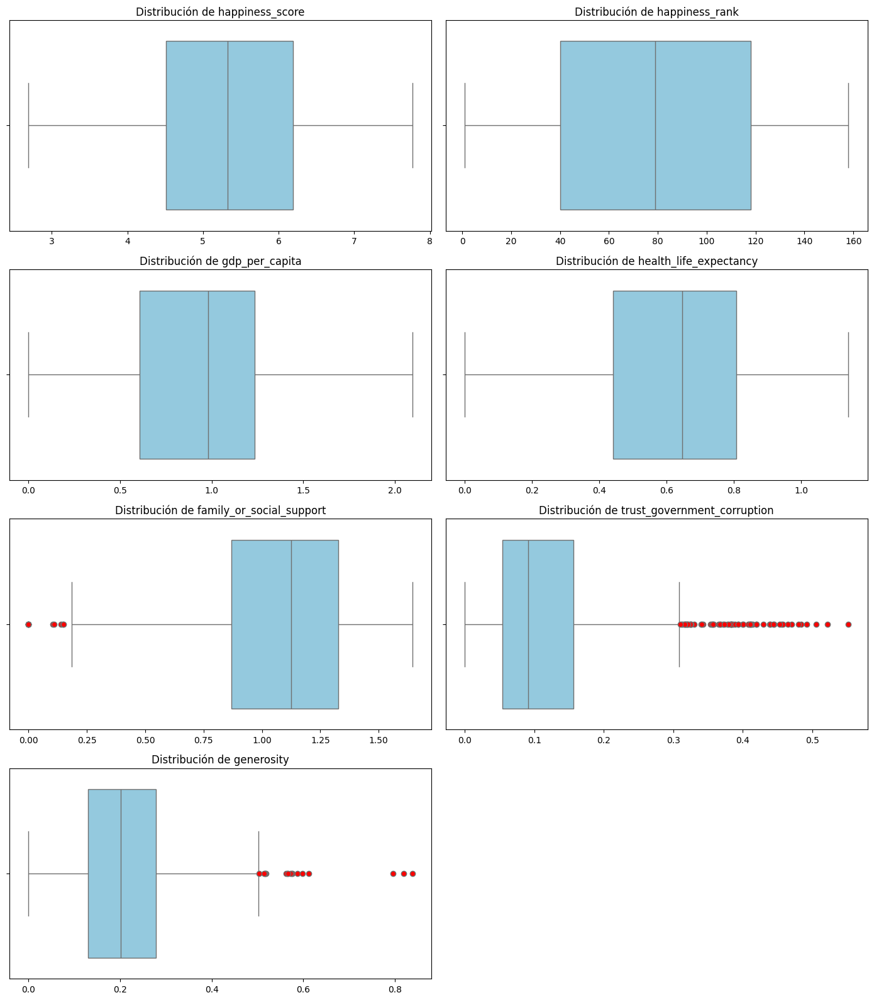

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Seleccionamos las columnas numéricas que queremos graficar
# Excluimos 'year' y 'record_id' ya que no representan magnitudes continuas de interés para boxplots individuales
columnas_numericas = feliz_union.select_dtypes(include=['float64', 'int64']).columns
columnas_a_graficar = [col for col in columnas_numericas if col not in ['year', 'record_id']]

# 2. Configuramos el tamaño de la figura en cuadrículas según el número de variables
num_columnas = len(columnas_a_graficar)
fig, axes = plt.subplots(nrows=(num_columnas + 1) // 2, ncols=2, figsize=(14, 4 * ((num_columnas + 1) // 2)))
axes = axes.flatten() # Aplanamos la matriz de ejes para iterar fácilmente

# 3. Generamos un diagrama de caja para cada variable numérica
for i, col in enumerate(columnas_a_graficar):
    sns.boxplot(data=feliz_union, x=col, ax=axes[i], color='skyblue', flierprops=dict(markerfacecolor='red', marker='o'))
    axes[i].set_title(f'Distribución de {col}', fontsize=12)
    axes[i].set_xlabel('')

# 4. Eliminamos los subplots sobrantes si el número de variables es impar
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Sin valores nulos <br>
Sin valores duplicados